# SCC.444 Analytics Assignment 2025-26
**Postgraduate**
### Masters Degree in Cyber Security - Individual Programming Assignment
### Recommended Completion Time \[8 Hours\]
### Assessment Weighting \[20%\]
### SCC.444 INFORMATION SECURITY RISK MANAGEMENT


___

## Assignment Overview:
You are a risk analyst working with a dataset of quarterly losses for several cyber and operational risks.
Your goal is to **assemble a full risk-analytics pipeline** using the techniques developed in the homework exercises — descriptive statistics, probability modelling, Monte Carlo simulation, and interpretation of executive risk-appetite data — to determine which risks should be prioritised for mitigation.

You may use **AI tools freely** (e.g., ChatGPT, Copilot, LM Studio) to assist with planning, debugging, or code explanation.
Higher marks depend on **your own interpretation and reasoning**.
If you only copy and run code, you will likely achieve no more than a Core (Pass) level.

### Key Points:

1. This is an 8-hour assignment. You are expected to **reuse functions and code patterns** from the homework exercises (data loaders, fitters, simulation scaffolds).
2. Your code must run on the SCC Scafell Virtual Machine in MyLabs. If it does not run here it will not be marked. **You should test this before submitting.**
3. If a Code Cell does not run on SCC Scafell then it *WILL NOT BE MARKED*. Random code dumped in a cell will not be considered.

___

## Task Guidance:
You have been provided with 10 years of event data for 6 risks in different risk data csv files.
Each row represents a 3 months, or a quarterly, report on the losses relating to the incidents of that risk type.

| Qtr | | | | |
| - | - | - | - | - |
| 1_Q1   | 100 | 30 | 1000 | 500 |
| 1_Q2   | 60  | 27 | 1100 | 450 |
| ...    | ... | ...| ...  | ... |
| 10_Q11 |     |    |      |     |
| 10_Q12 | 300 |    |      |     | 

The File name is an underscore separated name of the risk for example ransomware_attack.csv

Using the data provided you must:
1. Model the frequency of events using the Poisson Distribution
2. Model the Impact of the losses as a LogNormal distribution
3. Provide a Monte Carlo simulation of the risks with each trial representing a quarter, or three month period, with 10000 trials
4. Complete each code section in this Notebook with the corresponding code to undertake the tasks identified

Note: **10 marks** are available for the quality of the code, for example: comments, error handling, code structure.

In [17]:
# INCLUDE ALL YOUR IMPORTS IN THIS CELL
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Task 1: Load the data and Calculate the simulation parameters  **\(20 Marks Total\)**
You are free to use any data structures you like to handle the data:
1. Load the data of each of the risk files **\(3 marks\)**
2. For each risk calculate the descriptive stats mean and std dev number of events per quarter, the mean and std dev of the loss amounts **\(8 Marks\)**
3. For each risk calculate the model parameters - the lambda value for the poisson distribution and the mu and sigma values for log normal distribution for the simulation **\(6 Marks\)**
4. Calculate the Inhernet Annual Expected Loss (I-ALE) for each risk and the total I-ALE for all the risks **\(3 Marks\)**
5. All this information needs to be printed clearly so the marker can see each of the values


In [18]:
""" 
In order to parse the values of the csv files I used a custom csv to dataframe parser, that is different from the typical tokenization function of pandas. 
I happend to use this because the number of events per file wasn't the same and I wasn't able to create dataframes using the legacy pandas library function 
efficiently (pd.read_csv).
Now each file is parsed line per line and then, based on the maximum number of events the specific attack had in a single quarter, it creates
a dataframe in which the empty spots are filled with np.Nan (basically the lines which didn't have all the events were patched with NaN values to facilitate 
the analysis and data iteration).
For each row, these dataframes have an index that refers to the quarter of the year in which the events happend and then it has several "measurment_*" columns
based on the maximum number of events the specific attack had in a single quarter.
"""

# Task 1.1 Load the files - Solution
def parse_to_wide_format(filepath):
    data = []
    max_values = 0
    
    # Find maximum number of values
    with open(filepath, 'r') as f:
        for line in f:
            if line.strip():
                parts = line.split(',')
                max_values = max(max_values, len(parts) - 1)
    
    # Create wide format rows
    with open(filepath, 'r') as f:
        for line in f:
            if line.strip():
                parts = line.split(',')
                identifier = parts[0]
                values = [float(v) if v.strip() else np.nan 
                         for v in parts[1:]]
                
                while len(values) < max_values:
                    values.append(np.nan)
                
                row = {'identifier': identifier}
                for i, val in enumerate(values, 1):
                    row[f'measurement_{i}'] = val
                data.append(row)
    
    return pd.DataFrame(data)

risks_dfs = {}

# Step 1: Load all files and create dictionary correctly
dos_attack_df = parse_to_wide_format('denial_of_service.csv')
hacking_attack_df = parse_to_wide_format('hacking_attempt.csv')
insider_attack_df = parse_to_wide_format('insider_threat.csv')
malware_attack_df = parse_to_wide_format('malware_infection.csv')
phishing_attack_df = parse_to_wide_format('phishing.csv')
ransomware_attack_df = parse_to_wide_format('ransomware_attack.csv')

# Correct dictionary creation
risks_dfs = {
    'dos': dos_attack_df,
    'hacking': hacking_attack_df,
    'insider': insider_attack_df,
    'malware': malware_attack_df,
    'phishing': phishing_attack_df,
    'ransomware': ransomware_attack_df
}

print(risks_dfs)

{'dos':    identifier  measurement_1  measurement_2  measurement_3  measurement_4
0        1_Q1      584532.03      617807.05      616726.18            NaN
1        1_Q2      645710.28            NaN            NaN            NaN
2        1_Q3      576780.72      600905.18      616402.17            NaN
3        1_Q4      610989.05      579128.26            NaN            NaN
4        2_Q1      579556.89      583284.02      613517.86      604213.93
5      2_Q2\n            NaN            NaN            NaN            NaN
6        2_Q3      630912.45            NaN            NaN            NaN
7        2_Q4      589316.16            NaN            NaN            NaN
8        3_Q1      592323.96      618033.96      582762.37            NaN
9      3_Q2\n            NaN            NaN            NaN            NaN
10       3_Q3      584606.90            NaN            NaN            NaN
11       3_Q4      632290.66      608029.80      622691.62            NaN
12     4_Q1\n            NaN  

In [19]:
# Task 1.2 Calculate the risk stats - Solution

""" Initialize empty data frame for summary and a dictionary to address each descriptive statistic to each attack 
(P.S. for usability and habit I addressed attacks as risks, even though I know the csv files data is made of losses caused from attacks) """

summary_df = None
descriptive_stats = {}

for risk_name, risk_df in risks_dfs.items():
    # Get measurement columns (exclude 'identifier')
    measurement_cols = [col for col in risk_df.columns 
                       if col.startswith('measurement_')]
    
    # Amount of events per quarter
    risk_df['num_events'] = risk_df[measurement_cols].notna().sum(axis=1)
    
    # Sum of losses per quarter
    risk_df['total_loss'] = risk_df[measurement_cols].sum(axis=1)
    
    # Mean loss per quarter
    risk_df['mean_loss'] = risk_df[measurement_cols].mean(axis=1)
    
    # Std dev of losses per quarter
    risk_df['std_loss'] = risk_df[measurement_cols].std(axis=1, ddof=1)
    
    # Calculate overall statistics for this risk
    descriptive_stats[risk_name] = {
        'mean_events_per_quarter': risk_df['num_events'].mean(),
        'std_events_per_quarter': risk_df['num_events'].std(),
        'mean_loss_amount': risk_df['total_loss'].mean(),
        'std_loss_amount': risk_df['total_loss'].std(),
        'total_events': risk_df['num_events'].sum(),
        'total_loss': risk_df['total_loss'].sum()
    }

data_summary_df = pd.DataFrame(descriptive_stats).T
data_summary_df.index.name = 'Risk Type'

print(data_summary_df)

            mean_events_per_quarter  std_events_per_quarter  mean_loss_amount  \
Risk Type                                                                       
dos                           1.725                1.198022      1.039167e+06   
hacking                       2.000                1.339728      2.002192e+04   
insider                       0.950                0.932325      1.876238e+05   
malware                       1.750                1.391365      3.564811e+04   
phishing                     10.125                3.089996      6.023975e+04   
ransomware                    3.375                2.059219      1.350171e+06   

            std_loss_amount  total_events   total_loss  
Risk Type                                               
dos           720180.710533          69.0  41566691.17  
hacking        13362.670345          80.0    800876.99  
insider       187295.879322          38.0   7504951.13  
malware        28989.228627          70.0   1425924.46  
phishing 

In [20]:
# Task 1.3 Calculate the model parameters - Solution

# I initialized a dataframe and dictionary to address each risk's model parameters.
modelparams_df = None
model_stats = {}

# For each risk I calculated its mu and sigma, based on the losses per quarter
for risk_name, risk_df in risks_dfs.items():

    measurement_cols = [col for col in risk_df.columns if col.startswith('measurement_')]
    all_losses = risk_df[measurement_cols].values.flatten()
    all_losses = all_losses[~np.isnan(all_losses)] 

    # I calculated the mu and sigma using the log value of the losses in order to have the parameters to draw 
    # loss values during the Monte Carlo simulation from a lognormal distribution
    mu = np.log(all_losses).mean()

    sigma = np.log(all_losses).std(ddof=1)

    model_stats[risk_name] = {
        'mu': mu,
        'sigma': sigma,
        # the lambda value has been calculated based on the information that I found online about the Poisson distribution 
        # where it is described as wether the variance or the mean of the number of events in a given interval (e.g., number of incidents per quarter)
        # https://en.wikipedia.org/wiki/Poisson_distribution
        # https://www.scribbr.co.uk/faqs/lambda-poisson-distribution/
        # https://www.geeksforgeeks.org/maths/poisson-distribution/
        'lambda': np.mean(risk_df['num_events'])
    }

modelparams_df = pd.DataFrame(model_stats).T


print(risks_dfs)
print(modelparams_df)

{'dos':    identifier  measurement_1  measurement_2  measurement_3  measurement_4  \
0        1_Q1      584532.03      617807.05      616726.18            NaN   
1        1_Q2      645710.28            NaN            NaN            NaN   
2        1_Q3      576780.72      600905.18      616402.17            NaN   
3        1_Q4      610989.05      579128.26            NaN            NaN   
4        2_Q1      579556.89      583284.02      613517.86      604213.93   
5      2_Q2\n            NaN            NaN            NaN            NaN   
6        2_Q3      630912.45            NaN            NaN            NaN   
7        2_Q4      589316.16            NaN            NaN            NaN   
8        3_Q1      592323.96      618033.96      582762.37            NaN   
9      3_Q2\n            NaN            NaN            NaN            NaN   
10       3_Q3      584606.90            NaN            NaN            NaN   
11       3_Q4      632290.66      608029.80      622691.62          

In [21]:
# Task 1.4 Calculating Annual Expected Inherent Loss - Solution

# I initialized a dictionary to address each risk's IALE and the use it to add the values that 
# I wanted to calculate to the dataframe created in the previous frame
IALE_stats = {}

"""  
To calculate the IALE i followed the definitions of IALE and ALE that I could find online
because the asset value and the exposure factor weren't given. 
Usually this data is provided by the security team and/or the finance department in an organization.
https://www.leancompliance.ca/post/cybersecurity-risk-an-overview-of-annual-loss-expectancy-ale
https://en.wikipedia.org/wiki/Annualized_loss_expectancy
https://netwrix.com/en/resources/blog/annual-loss-expectancy-and-quantitative-risk-analysis/

The mean of the number of events per risk (quarterly rate of occurrence - QRO) is important to calculate the IALE, 
because once you multiply it with the mean of the losses (Single Loss Expectancy - SLE) per risk you obtain the IALE per quarter of each risk
Therefore you can use it for:
- IALE per risk, per year (multiply it × 4 for each risk)
- Total IALE of all risks per quarter (summing every IALE per quarter of each risk) 
- Total IALE of all risks per year (multiplying the previously calculated IALE × 4 or summing up the total IALE per risk per year) 
"""
for risk_name, risk_df in risks_dfs.items():

    measurement_cols = [col for col in risk_df.columns if col.startswith('measurement_')]
    all_losses = risk_df[measurement_cols].values.flatten()
    all_losses = all_losses[~np.isnan(all_losses)] 

    lmb = modelparams_df.loc[risk_name, 'lambda']

    # Rate of occurrence per quarter of each risk
    QRO = lmb

    # Single loss expectancy of each risk based on all the losses 
    SLE = np.mean(all_losses)

    # I calculate the IALE based on the rate of occurrence per quarter and 
    # estimating the SLE assuming it is the mean of all the losses 
    IALE_per_quarter = QRO * SLE

    # using Poisson to calculate te quarterly event probability 
    # (I calculated this value to have more reference for my personal point of view, 
    # I didn't use this value in any other point of the data analysis at all)
    Event_Quart_Prob = 1 - np.exp(-lmb)

    IALE_stats[risk_name] = {
        'IALE': IALE_per_quarter,
        'Event_Probability_Per_Quarter': Event_Quart_Prob
    }

iale_df = pd.DataFrame(IALE_stats).T

modelparams_df['IALE'] = iale_df['IALE']
modelparams_df['Event_Probability_Per_Quarter'] = iale_df['Event_Probability_Per_Quarter']

Total_Risk_IALE = modelparams_df['IALE'].sum() * 4

print(modelparams_df)


                   mu     sigma  lambda          IALE  \
dos         13.308052  0.036361   1.725  1.039167e+06   
hacking      9.211388  0.009909   2.000  2.002192e+04   
insider     12.192213  0.051073   0.950  1.876238e+05   
malware      9.910347  0.152853   1.750  3.564811e+04   
phishing     8.677515  0.164901  10.125  6.023975e+04   
ransomware  12.899343  0.002501   3.375  1.350171e+06   

            Event_Probability_Per_Quarter  
dos                              0.821827  
hacking                          0.864665  
insider                          0.613259  
malware                          0.826226  
phishing                         0.999960  
ransomware                       0.965782  


## Task 2: Run a Monte Carlo Simulation of the risks  **\(30 Marks Total\)**
Complete the following tasks
1. Create a 10000 trial monte carlo simulation where each trial is a quarter (3 months) **\(8 Marks\)**
2. What is the max, min, mean, median, std deviation, IQR of the simulated total quarterly loss **\(2 Marks\)**
3. What is the max, min, mean, median, std deviation, IQR of the simulated total quarterly events **\(2 Marks\)**
4. Calculate the Simulated ALEs (S-ALE) for each risk and the total risk **\(2 Marks\)**
5. Produce a suitable probability density histogram with 500 bins for the total quarterly loss **\(3 Marks\)**
6. Produce a suitable probability density histogram with 50 bins for the total quarterly events **\(3 Marks\)**
7. Produce a single plot with a loss exceedance curve for each risk **\(5 Marks\)**
8. Produce a plot with a loss exceedance curve for the total loss **\(2 Marks\)**
9. What is probability (to 2 decimal places) of losses in a single quarter exceeding **\(3 Marks\)**:
    - £5000
    - £25000
    - £1000000

In [22]:
# Task 2.1 Monte Carlo Simulation - Solution

# I initialized a dictionary to store the different dataframes for each risk simulation 
# along with a summary dataframe to summarize the losses and the number of events
MC_dfs = {}
MC_summary_df = None

rng = np.random.default_rng()
number_of_trials = 10000

# A list of the risk names based on the model parameter dataframe indexes
risks_name_list = list(modelparams_df.index)

# Dictionary to address all the simulation results individually to each of the risk
risk_mc_results = {risk_name: [] for risk_name in risks_name_list}

for q in range(number_of_trials):

    for risk_name in risks_name_list:

        lm = modelparams_df.loc[risk_name, 'lambda']
        mu = modelparams_df.loc[risk_name, 'mu']
        sigma = modelparams_df.loc[risk_name, 'sigma']

        # Drawing the number of events from a Poisson distribution
        n_of_events = np.random.poisson(lam=lm)

        # Draw losses for each event (lognormal)
        if n_of_events > 0:
            losses = rng.lognormal(mean=mu, sigma=sigma, size=n_of_events)
            total_loss = np.sum(losses)
        else:
            total_loss = 0
        
        # Store this trial's result for this risk
        risk_mc_results[risk_name].append([total_loss, n_of_events])


# Convert results to dataframes and store in dictionary
for risk_name in risks_name_list:
    MC_dfs[risk_name] = pd.DataFrame(
        risk_mc_results[risk_name], 
        columns=['Total Loss', 'Total Events']
    )

# Summary dataframe population
summary_results = []

for trial_index in range(number_of_trials):

    total_loss_across_risks = 0
    total_events_across_risks = 0

    for risk_name in risks_name_list:
        risk_df = MC_dfs[risk_name]
        trial_row = risk_df.iloc[trial_index]
        
        total_loss_across_risks += trial_row['Total Loss']
        total_events_across_risks += trial_row['Total Events']

    summary_results.append([total_loss_across_risks, total_events_across_risks])

    MC_summary_df = pd.DataFrame(summary_results, columns=['Experienced Losses', 'Experienced Events'])

    MC_dfs['summary'] = MC_summary_df

# Check the results
print("Summary DataFrame:")
print(MC_summary_df)

Summary DataFrame:
      Experienced Losses  Experienced Events
0           5.248229e+05                17.0
1           1.291808e+06                14.0
2           2.560249e+06                24.0
3           2.405444e+06                25.0
4           2.866371e+06                15.0
...                  ...                 ...
9995        1.271567e+06                13.0
9996        7.537837e+05                19.0
9997        2.968177e+06                26.0
9998        2.488007e+06                18.0
9999        2.134101e+06                20.0

[10000 rows x 2 columns]


In [23]:
# Task 2.2 Descriptive Stats Loses - Solution

data_losses = MC_summary_df['Experienced Losses'].to_numpy()
# MC simulation losses mean
trial_total_losses_mean = np.mean(data_losses)
# MC simulation losses median
trial_total_losses_median = np.median(data_losses)
# MC simulation losses standard deviation
trial_total_losses_stddev = np.std(data_losses)
# MC simulation losses minimum valuea
trial_total_losses_min = np.min(data_losses)
# MC simulation losses max value
trial_total_losses_max = np.max(data_losses)

Q3L = np.percentile(data_losses, 75)
Q1L = np.percentile(data_losses, 25)
# MC simulation losses IQR
trial_total_losses_IQR = Q3L - Q1L

print(f'MC simulation losses mean: {trial_total_losses_mean}')
print(f'MC simulation losses median: {trial_total_losses_median}')
print(f'MC simulation losses standard deviation: {trial_total_losses_stddev}')
print(f'MC simulation losses minimum value: {trial_total_losses_min}')
print(f'MC simulation losses max value: {trial_total_losses_max}')
print(f'MC simulation losses IQR: {trial_total_losses_IQR}')

MC simulation losses mean: 2692990.8319736295
MC simulation losses median: 2618489.5682434994
MC simulation losses standard deviation: 1084756.3648556492
MC simulation losses minimum value: 54706.059592492085
MC simulation losses max value: 7468845.969111156
MC simulation losses IQR: 1459560.5883197808


In [24]:
# Task 2.3 Descriptive Stats Events - Solution

data_events = MC_summary_df['Experienced Events'].to_numpy()
# MC simulation events mean
trial_incidents_mean = np.mean(data_events)
# MC simulation events median
trial_incidents_median = np.median(data_events)
# MC simulation events standard deviation
trial_incidents_stddev = np.std(data_events)
# MC simulation events minimum value
trial_incidents_min = np.min(data_events)
# MC simulation events mav
trial_incidents_max = np.max(data_events)

Q3L = np.percentile(data_events, 75)
Q1L = np.percentile(data_events, 25)
# MC simulation events IQR
trial_incidents_IQR = Q3L - Q1L

print(f'MC simulation events mean: {trial_incidents_mean}')
print(f'MC simulation events median: {trial_incidents_median}')
print(f'MC simulation events standard deviation: {trial_incidents_stddev}')
print(f'MC simulation events minimum value: {trial_incidents_min}')
print(f'MC simulation events max value: {trial_incidents_max}')
print(f'MC simulation events IQR: {trial_incidents_IQR}')

MC simulation events mean: 19.93
MC simulation events median: 20.0
MC simulation events standard deviation: 4.465254751971045
MC simulation events minimum value: 5.0
MC simulation events max value: 37.0
MC simulation events IQR: 6.0


In [25]:
# Task 2.4 Calculating the Simulated Annualised Loss Expectancies - Solution

S_ALE_per_risk = {}

for risk_name in risks_name_list:
    risk_mc_df = MC_dfs[risk_name]
    
    simulated_ALE_per_quarter = np.mean(risk_mc_df['Total Loss'])
    
    S_ALE_per_risk[risk_name] = {
        'Simulated ALE per risk, per quarter': simulated_ALE_per_quarter
    }

simulated_ALE_df = pd.DataFrame(S_ALE_per_risk).T
print(simulated_ALE_df)

print('\n')

total_S_ALE = np.mean(MC_summary_df['Experienced Losses']) * 4
print('Total S-ALE (Simulated Annual Loss Expectancy):')
print(total_S_ALE)
print('For comparison, actual Total IALE (Inherent Annual Loss Expectancy):')
print(Total_Risk_IALE)

print('\n')

print('Total S-ALE per quarter:')
print(simulated_ALE_df['Simulated ALE per risk, per quarter'].sum())
print('For comparison, actual Total IALE per quarter:')
print(Total_Risk_IALE / 4)


            Simulated ALE per risk, per quarter
dos                                1.034255e+06
hacking                            1.999610e+04
insider                            1.883947e+05
malware                            3.531054e+04
phishing                           6.033469e+04
ransomware                         1.354700e+06


Total S-ALE (Simulated Annual Loss Expectancy):
10771963.327894518
For comparison, actual Total IALE (Inherent Annual Loss Expectancy):
10771487.955


Total S-ALE per quarter:
2692990.83197363
For comparison, actual Total IALE per quarter:
2692871.98875


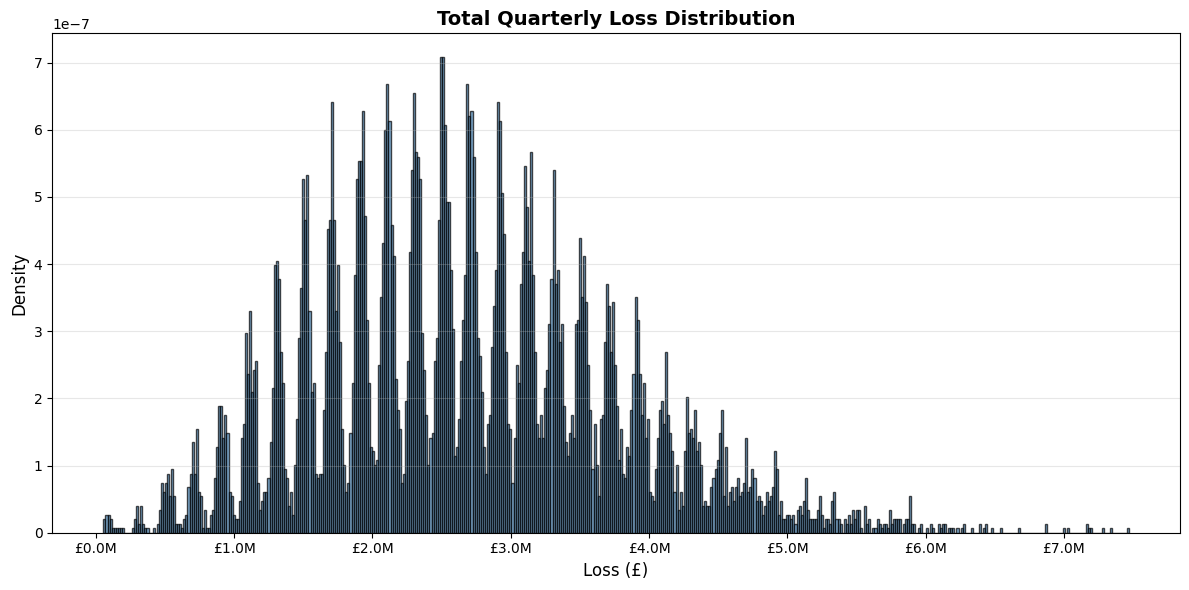

In [26]:
# Task 2.5 Histogram Loss - Solution

from matplotlib.ticker import FuncFormatter

# Function to format the x axis labels for an easier reading (instead of the scientific notation)
def millions(x, pos):
    return f'£{x*1e-6:.1f}M'

# Create professional histogram
plt.figure(figsize=(12, 6))
plt.hist(data_losses, bins=500, edgecolor='black',color='steelblue', alpha=0.7, density=True)
ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(millions))
plt.title('Total Quarterly Loss Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Loss (£)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


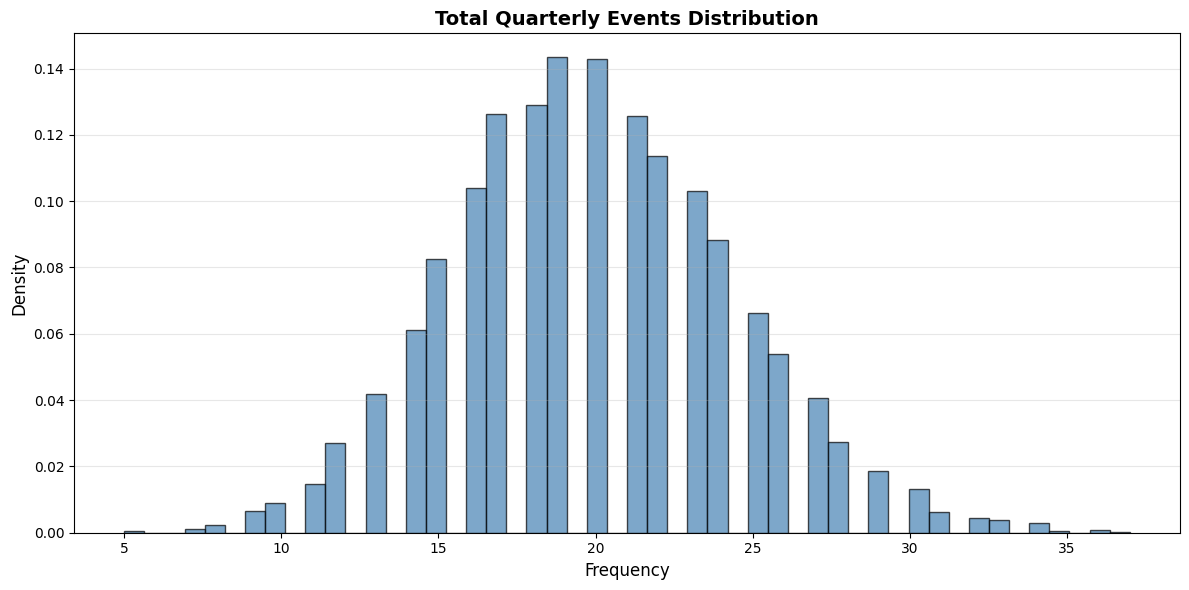

In [27]:
# Task 2.6 Histogram Events - Solution
plt.figure(figsize=(12, 6))
plt.hist(data_events, bins=50, edgecolor='black', color='steelblue', alpha=0.7, density=True)
plt.title('Total Quarterly Events Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

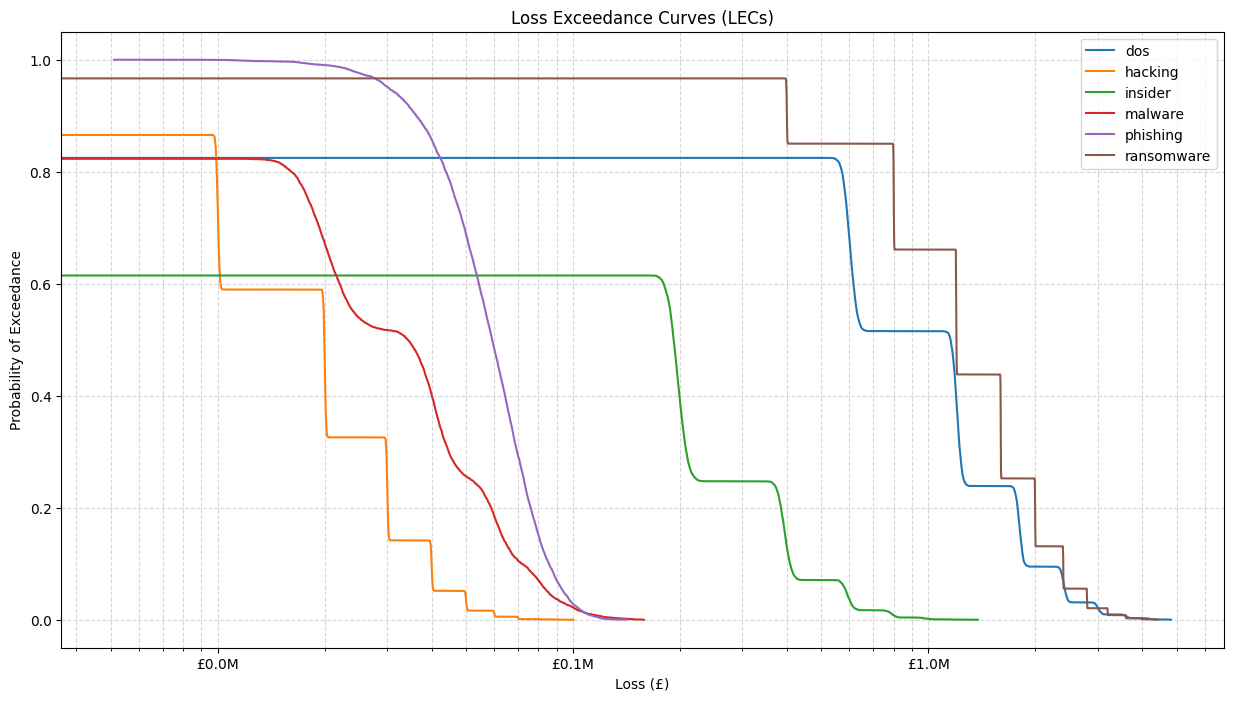

In [28]:
# Task 2.7 LECs for each risk

def plot_lec(losses, label, color=None):
    # Step 1: Sort the losses
    sorted_losses = np.sort(losses)[::-1]
    # Step 2: Compute exceedance probabilities (CCDF)
    exceedance = np.arange(1, len(sorted_losses)+1) / len(sorted_losses) 
    # Step 3: Plot (log x is common when tail is interesting)
    plt.plot(sorted_losses, exceedance, label=label, color=color)


plt.figure(figsize=(15, 8))

# For each risk, plot LEC
for risk_name in risks_name_list:  
    losses = MC_dfs[risk_name]['Total Loss'].to_numpy()
    plot_lec(losses, label=risk_name)

plt.xscale('log')
plt.xlabel('Loss (£)')
ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(millions))
plt.ylabel('Probability of Exceedance')
plt.title('Loss Exceedance Curves (LECs)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

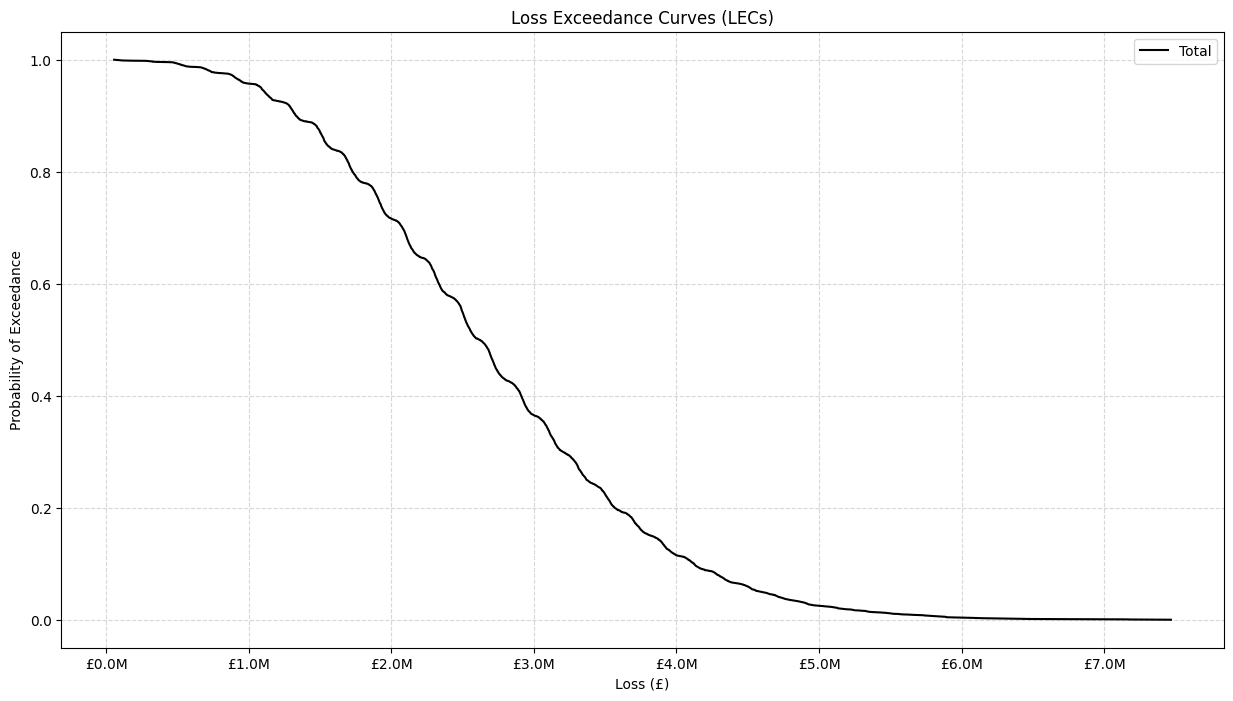

In [29]:
# Task 2.8 LEC for the total - Solution
# Total losses

plt.figure(figsize=(15, 8))
total_losses = MC_summary_df['Experienced Losses'].to_numpy()
plot_lec(total_losses, label='Total', color='black')


ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(millions))
plt.xlabel('Loss (£)')
plt.ylabel('Probability of Exceedance')
plt.title('Loss Exceedance Curves (LECs)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


In [30]:
# Task 2.9 Proabilities to exceed a set of values - Solution
loss_amounts = [5000, 25000, 1000000]

total_losses = MC_summary_df['Experienced Losses']

min_loss = MC_summary_df['Experienced Losses'].min()

print(f'Minimum total loss per quarter £{min_loss:.2f}')

for loss in loss_amounts:
    prob = np.mean((total_losses > loss))
    print(f"Probability of exceeding £{loss:,.0f}: {prob:.2f}")


Minimum total loss per quarter £54706.06
Probability of exceeding £5,000: 1.00
Probability of exceeding £25,000: 1.00
Probability of exceeding £1,000,000: 0.96


# Task 3: Control Target  **\(20 Marks Total\)**
Question: Which are the most and least important risks to deal with and explain your reasoning. **You should provide your answer in this markdown cell.**  **\(20 Marks\)**

*Answer: Based on the S-ALE calculated during the simulation and the AEIL derived from the given data, the risk of getting attacked with a ransomware is the biggest measurable concern, because its Simulated ALE per quarter is about £1.35M and its worst case loss (VaR 95%) is £2.8M per quarter, so in terms of insurance and board decisions the data shows that the ransomware is the most critical thing to deal with and prioritize. Instead the least important one is the risk of hacking attempt that has a S-ALE and AEIL per quarter of £20k and its worst case loss (VaR 95%) is £50k per quarter.*

**There are lots of ways to do this. The AEIL is one way which can be used which is the basic answer, but there are multiple ways using the simulated data. using the data is a better approach. Examples given below**

1. Using the AEIL calculated earlier
2. Rank based on the simulated Quarterly inherent loss (Annual would be the same result as it is just 4 times the expected quarterly loss)
3. Rank based on quarterly probability of exceeding certain thresholds
4. Value at risk above a certain threshold normally 95%
5. Sensitivity analysis using correlation perhaps.

In [31]:
ranking_df = pd.DataFrame({
    # Simulated annual loss expectancy per risk, per quarter
    'S-ALE': simulated_ALE_df['Simulated ALE per risk, per quarter'],
    # Worst case loss scenario(95%)
    'VaR 95%': [MC_dfs[risk]['Total Loss'].quantile(0.95) for risk in risks_name_list],
    # Values to asses the volatility of the risks
    'Std Dev': [MC_dfs[risk]['Total Loss'].std(ddof=1) for risk in risks_name_list],
    # The biggest simulated loss addressed to the 
    'Max Loss': [MC_dfs[risk]['Total Loss'].max() for risk in risks_name_list],
    # Number of events in the simulation, for reference
    'Number of Events': [MC_dfs[risk]['Total Events'].mean() for risk in risks_name_list],
    #Actual IALE from the given data
    'Actual IALE': modelparams_df['IALE']
})

print(ranking_df.sort_values('S-ALE', ascending=False))
print('\n')

print(simulated_ALE_df.sort_values('Simulated ALE per risk, per quarter', ascending=False))
print('\n')
# Total Simulated ALE average per quarter
total_S_ALE = np.mean(MC_summary_df['Experienced Losses'])

print('Total S-ALE per quarter mean:')
print(total_S_ALE)
print('For comparison, actual Total IALE per quarter:')
print(Total_Risk_IALE / 4)


                   S-ALE       VaR 95%        Std Dev      Max Loss  \
ransomware  1.354700e+06  2.797310e+06  733657.895599  4.406465e+06   
dos         1.034255e+06  2.432452e+06  786454.700904  4.822188e+06   
insider     1.883947e+05  5.882767e+05  193876.029450  1.380069e+06   
phishing    6.033469e+04  9.419830e+04   19304.641348  1.409510e+05   
malware     3.531054e+04  8.497663e+04   27124.578899  1.583480e+05   
hacking     1.999610e+04  4.964704e+04   14175.023093  1.002346e+05   

            Number of Events   Actual IALE  
ransomware            3.3863  1.350171e+06  
dos                   1.7166  1.039167e+06  
insider               0.9541  1.876238e+05  
phishing             10.1428  6.023975e+04  
malware               1.7331  3.564811e+04  
hacking               1.9971  2.002192e+04  


            Simulated ALE per risk, per quarter
ransomware                         1.354700e+06
dos                                1.034255e+06
insider                            1.8839

___

## Task 4: Reflection and Responsible AI Use **(20 Marks)**

1. Record which AI tool you used and log key prompts 
2. Explain what you have have leared while using AI; where AI helped/hindered; how you verified outputs; key assumptions/limitations

### Task 4.1 AI Use Log

Activity: Log which AI tool you have used and your key prompts to help you with this activity. **Write your content in this markdown section.**

*Write Response Below Here:*

**AI usage disclosure:**

I have used Perplexity (Pro Version) to:
- understand what was going on with csv file reading
- understand what errors I was doing while using datframes and dictionaries as data structures
- understand how to adapt previous code snippets made for the assignments
- clear my ideas
- feedback
- acknowledge statics notions

#### Key Logs:
**Log.1**

"How can I read a non-typical csv file with pandas?
```python
I have several file wich format is:
1_Q1,584532.03,617807.05,616726.18
1_Q2,645710.28
1_Q3,576780.72,600905.18,616402.17
1_Q4,610989.05,579128.26
2_Q1,579556.89,583284.02,613517.86,604213.93
2_Q2
2_Q3,630912.45
2_Q4,589316.16
3_Q1,592323.96,618033.96,582762.37
3_Q2
..
..
..
```

They all are made of 40 lines, each of them represents 3 months of a year, a quarter (tot. 10 year)"

**Log.2**

"What is the Inherent Annual Loss Expectancy? Why is it different from ALE?"

**Log.3**

"Why sigma is zero?"

**Log.4**

"The LECs seem kind of off and the S-ALE isn't similar to the IALE. Maybe the way I am calculating lambda values is wrong, but I know that all the counting and that processing and loading of the data from the files is done correctly (e.g. the count of the number of events per risk). What should I change? Check this code snippet:"


### Task 4.2 AI Reflection

Activity: Reflect on your use of AI in this activity. **Write your content in this markdown section.**

*Write Response Below Here:*

I learnt and understood a lot of key concepts during this coursework when aided by AI. 
Obviously, the biggest effort was doing the homework during the previous week and I can say that, thanks to that, more than the 80% of the work was done because I knew the logic and how to apply it, but often I was doubting my knowledge and AI came in clutch to have a reference for instant feedback. 
Nevertheless, I had to search online personally for academic references (e.g. papers or books) and known websites to verify my assumptions and avoid wrong outputs made by the AI that sometimes can hallucinate. Matter of fact, I had to argue with the LLM because it was giving wrong indications for no reason at all, going also against what it said previously in the same chat!
Having a tool like this is really helpful for bug hunting, troubleshooting, planning, refactoring and fast learning but while using it you must be self conscious about what you are actually doing and never fully rely on the AI output.
A best practice to adopt to get even better and trustworthy results is to critically question every output that it gives, first analyzing it, and then searching for eventual errors in the logic behind the output itself.

Overall I used it to calrify my ideas, to correct my code, to discuss my assumption, to get feedback and also to review key concepts about statistics (e.g. to understand the poisson distribution I used during the Monte Carlo simulations).

